# Respiration processing test
Demo of `src/rsp/resp_processing.py` on one cohort 3 cagemate session.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[2]  # repo root (notebook lives in src/<pkg>/test)
sys.path.insert(0, str(ROOT))
H5 = ROOT / "exports/cagemate_h5/cohort3_bla_cohort2_CM/11_4_d_CM_11_3_s_20260729_125055.h5"
from src.rsp import resp_processing as rp

## `load_raw_resp`
Raw 20 kHz pressure trace from the H5.

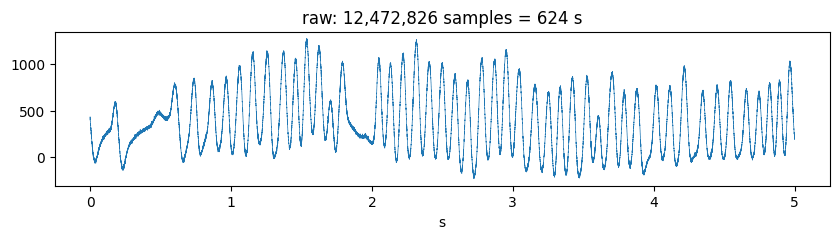

In [2]:
raw = rp.load_raw_resp(H5)
t_raw = np.arange(raw.size) / rp.RAW_FS
m = t_raw < 5
plt.figure(figsize=(10, 2)); plt.plot(t_raw[m], raw[m], lw=0.5)
plt.title(f"raw: {raw.size:,} samples = {raw.size / rp.RAW_FS:.0f} s"); plt.xlabel("s"); plt.show()

## `preprocess_resp`
Center, clip, low-pass, downsample to 100 Hz, band-pass 0.1–20 Hz.

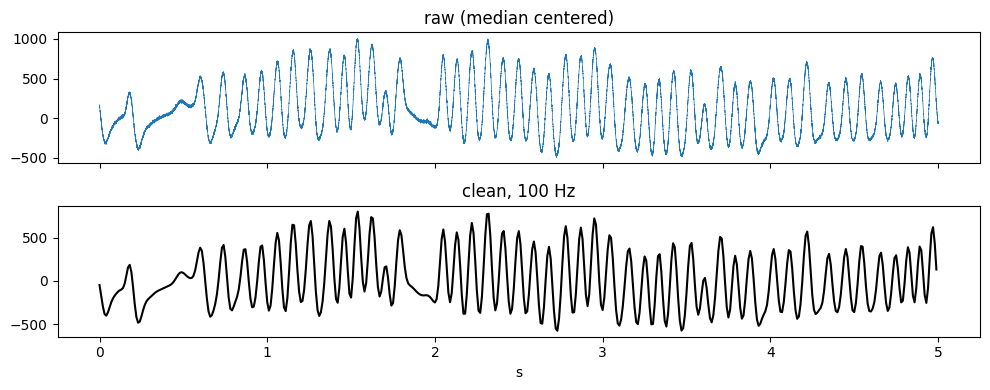

In [3]:
resp, t = rp.preprocess_resp(raw)
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(t_raw[m], raw[m] - np.median(raw), lw=0.5); ax[0].set_title("raw (median centered)")
ax[1].plot(t[t < 5], resp[t < 5], color="k"); ax[1].set_title(f"clean, {rp.TARGET_FS} Hz")
ax[1].set_xlabel("s"); plt.tight_layout(); plt.show()

## `detect_breaths`
Breath peaks in one phase, at least 80 ms apart.

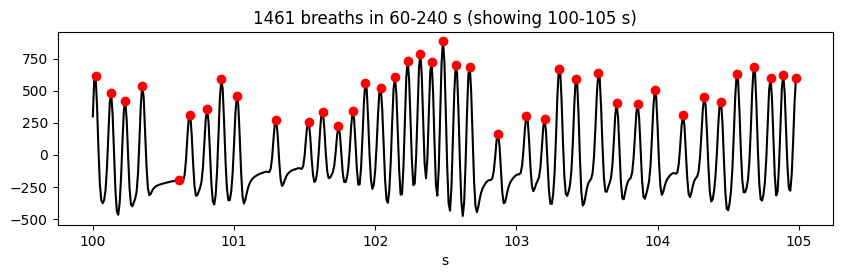

In [4]:
peaks = rp.detect_breaths(resp, t, 60, 240)
w = (t >= 100) & (t < 105)
plt.figure(figsize=(10, 2.5)); plt.plot(t[w], resp[w], color="k")
p = peaks[(t[peaks] >= 100) & (t[peaks] < 105)]
plt.plot(t[p], resp[p], "ro"); plt.title(f"{len(peaks)} breaths in 60-240 s (showing 100-105 s)")
plt.xlabel("s"); plt.show()

## `breathing_rate`
Mean breathing rate per phase.

In [5]:
for start, end in [(0, 60), (60, 240), (240, 600)]:
    pk = rp.detect_breaths(resp, t, start, end)
    print(f"{start:>3}-{end:<3} s: {len(pk):5d} breaths, {rp.breathing_rate(t, pk):.2f} Hz")

  0-60  s:   519 breaths, 9.45 Hz
 60-240 s:  1461 breaths, 8.93 Hz
240-600 s:  2951 breaths, 9.03 Hz


## How to use
Typical analysis: breathing rate per phase for a list of sessions.

In [6]:
import pandas as pd
from src.rsp.resp_processing import load_raw_resp, preprocess_resp, detect_breaths, breathing_rate

sessions = [H5]  # list of H5 paths
phases = {"early": (0, 60), "middle": (60, 240), "late": (240, 600)}

rows = []
for h5 in sessions:
    resp, t = preprocess_resp(load_raw_resp(h5))
    for phase, (start, end) in phases.items():
        peaks = detect_breaths(resp, t, start, end)
        rows.append({"session": Path(h5).stem, "phase": phase,
                     "n_breaths": len(peaks), "rate_hz": breathing_rate(t, peaks)})
pd.DataFrame(rows)

,session,phase,n_breaths,rate_hz
0,11_4_d_CM_11_3_s_20260729_125055,early,519,9.454969
1,11_4_d_CM_11_3_s_20260729_125055,middle,1461,8.928840
2,11_4_d_CM_11_3_s_20260729_125055,late,2951,9.034636
